# Hipótesis sobre el dataset canónico

Ciencia de Datos · UTN FRM · 2026

El notebook de EDA terminó con preguntas abiertas. Acá las convertimos en hipótesis:
afirmaciones que pueden resultar falsas, con una medida que las contesta y una decisión
que sale de esa medida.

Seis hipótesis resueltas de punta a punta. Se corre de arriba hacia abajo, y no hace falta
haber corrido el notebook de EDA: todo lo que se usa acá se calcula acá.

# Sección 1: Las dos preguntas

Toda hipótesis de esta unidad nace de una de dos preguntas, y conviene saber de cuál,
porque terminan en cosas distintas.

**Qué queremos responder** es la pregunta de negocio: qué determina el valor de un jugador.
Termina en una conclusión. **Qué queremos predecir** es la de modelado: la posición, que es
el objetivo del modelo de la Unidad 3. Termina en una decisión sobre qué columnas usar.

### El dataset

In [ ]:
# El dataset se baja del Drive de la cátedra la primera vez que se corre el notebook
import os

ARCHIVO  = "fifa_canonico_2026-07-23.csv"
ID_DRIVE = "1cF30_fSvxNKpK5-AKJlzUqLHZTTUf0ls"

if not os.path.exists(ARCHIVO):
    !gdown $ID_DRIVE -O $ARCHIVO


In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

df = pd.read_csv(ARCHIVO, low_memory=False)

### La misma columna cambia de rol

`value_eur` es el objetivo de la pregunta de negocio: todo lo demás se usa para explicarlo.
Para la pregunta de modelado es apenas una columna más, y en la Sección 4 vamos a ver que
además es de las peores. Saber cuál de las dos preguntas estás contestando decide qué papel
juega cada columna, y no al revés.

In [ ]:
# Valor mediano por posición: objetivo de una pregunta, columna cualquiera de la otra
df.groupby("best_position")["value_eur"].median().sort_values(ascending=False).head()

,value_eur
best_position,
CF,2050000.0
CM,1500000.0
LWB,1500000.0
RWB,1500000.0
LW,1400000.0


# Sección 2: Cómo se plantea una hipótesis

Una hipótesis no se contesta con un gráfico: se contesta con **un número**, y el gráfico
explica ese número. La razón es que un gráfico no se compara contra nada. Dos boxplots
pueden parecer distintos y ser lo mismo, o parecer iguales y esconder una diferencia
enorme, según cuánto se estire el eje. Un número, en cambio, se compara contra un corte
fijado de antemano, y por eso puede decir *terminá acá*.

### La regla del orden

La afirmación y lo que esperás ver se escriben **antes** de correr la medida. Podés usar
todo lo que ya sabías —lo que viste en el EDA, lo que sabés de fútbol, lo que te dijo
alguien— pero no el resultado que estás por calcular. Si al releer tu hipótesis se nota que
la escribiste después de mirar el gráfico, no estás poniendo a prueba nada: estás
describiendo lo que viste.

### Las tres plantillas

Casi todo lo que uno quiere preguntarle a una tabla entra en una de tres formas, y **la
forma trae su medida**. Ese es todo el truco: si sabés en qué plantilla cae tu hipótesis,
ya sabés qué número tenés que calcular, y no lo elegís después de ver cuál te conviene.

| Forma | Se escribe | Medida |
|---|---|---|
| Comparación | «*X* difiere entre *A* y *B*» | separación estandarizada, o η² con varios grupos |
| Asociación | «*X* se mueve junto con *Y*» | Pearson y Spearman |
| Composición | «*C* está sobrerrepresentada en *G*» | proporción del grupo contra la global |

Las tres se calculan abajo. Vale la pena entender qué significa cada número antes de
usarlo, porque el semáforo de más adelante corta sobre esos valores.

### Comparación de dos grupos: la separación estandarizada

Restar dos promedios no dice nada por sí solo: ocho centímetros son muchos entre personas y
nada entre edificios. La separación divide esa diferencia por cuánto varían los datos, así
que el resultado se lee siempre igual, en **desviaciones estándar**, y se puede comparar
entre variables que no tienen nada que ver.

In [ ]:
def separacion(x, y):
    """Distancia entre dos muestras, en desviaciones estándar."""
    x, y = x.dropna(), y.dropna()
    return abs(x.mean() - y.mean()) / np.sqrt((x.std() ** 2 + y.std() ** 2) / 2)

Dos casos de altura, para ver la escala. Los arqueros son ocho centímetros más altos
que el resto y los diestros poco más de un centímetro más altos que los zurdos: la
separación distingue lo que se nota a simple vista de lo que sólo existe en el promedio.

In [ ]:
alto_gk = separacion(df.loc[df["best_position"] == "GK", "height_cm"],
                     df.loc[df["best_position"] != "GK", "height_cm"])
alto_pie = separacion(df.loc[df["preferred_foot"] == "Left",  "height_cm"],
                      df.loc[df["preferred_foot"] == "Right", "height_cm"])

pd.Series({"arqueros vs resto": alto_gk, "zurdos vs diestros": alto_pie}).round(3)

,0
arqueros vs resto,1.431
zurdos vs diestros,0.176


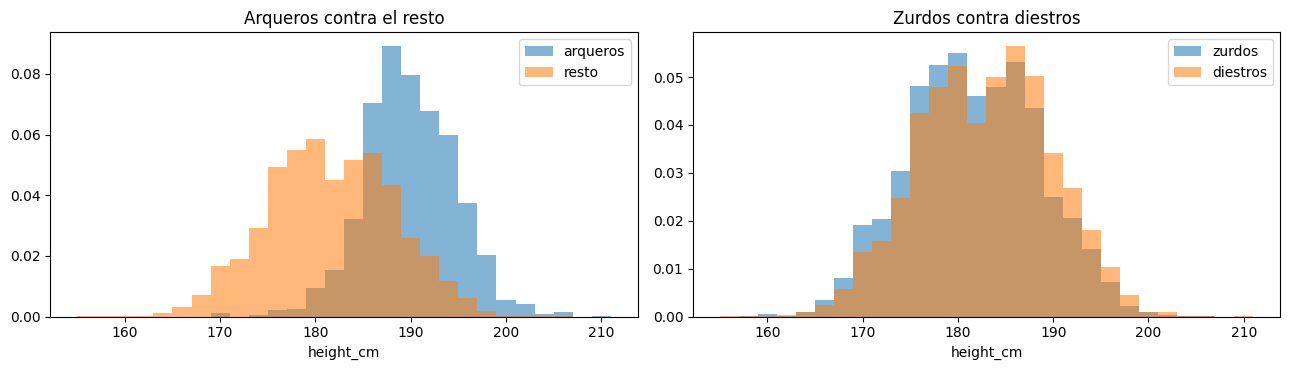

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(13, 3.8), sharex=True)
bins = np.arange(155, 212, 2)

grupos = [(df["best_position"] == "GK",     "arqueros", "resto",    "Arqueros contra el resto"),
          (df["preferred_foot"] == "Left",  "zurdos",   "diestros", "Zurdos contra diestros")]

for ax, (mascara, a, b, titulo) in zip(axes, grupos):
    ax.hist(df.loc[mascara,  "height_cm"], bins=bins, alpha=.55, density=True, label=a)
    ax.hist(df.loc[~mascara, "height_cm"], bins=bins, alpha=.55, density=True, label=b)
    ax.set_title(titulo); ax.set_xlabel("height_cm"); ax.legend()

plt.tight_layout()
plt.show()

### Comparación de muchos grupos: η²

Con más de dos grupos la resta ya no alcanza. η² —la razón de correlación— responde otra
pregunta: **qué proporción de la variación total de la columna numérica se explica por a
qué grupo pertenece cada fila**. Va de 0 a 1. Si vale 0, saber el grupo no ayuda en nada a
adivinar el valor; si vale 1, el grupo lo determina por completo.

In [ ]:
def eta2(numerica, categoria):
    """Proporción de la varianza de la numérica que explica la categoría."""
    g = numerica.groupby(categoria)
    m = numerica.mean()
    return (g.count() * (g.mean() - m) ** 2).sum() / ((numerica - m) ** 2).sum()

In [ ]:
# Dos extremos: la posición explica casi toda la variación de una y casi nada de la otra
pd.Series({"reflejos": eta2(df["goalkeeping_reflexes"], df["best_position"]),
           "valor":    eta2(df["value_eur"],            df["best_position"])}).round(3)

,0
reflejos,0.952
valor,0.012


### Asociación entre dos numéricas: Pearson, Spearman y la brecha

Pearson mide cuánto se parece la nube a **una recta**. Spearman hace lo mismo pero sobre los
puestos en el ranking, así que mide si una sube cada vez que la otra sube, con recta o sin
ella. De ahí sale lo interesante: cuando Spearman es mucho más alto que Pearson, la relación
existe y es ordenada pero **no es recta**. Esa brecha es un detector de curvatura.


In [ ]:
def asociacion(x, y):
    """Pearson, Spearman y la brecha entre ambos."""
    p, s = x.corr(y), x.corr(y, method="spearman")
    return pd.Series({"pearson": p, "spearman": s, "brecha": s - p}).round(3)

### Composición: proporciones comparadas

La tercera plantilla no necesita función propia. Se calcula una proporción dentro de un
grupo y se la compara contra la proporción global: si la categoría representa el 12 % del
total y el 40 % de un grupo, está sobrerrepresentada. Es la forma de la hipótesis H5.

### El semáforo

Falta la parte que convierte un número en una decisión. Y hay un motivo por el que hace
falta: con 18.936 filas **casi cualquier diferencia da estadísticamente significativa**. La
prueba de hipótesis clásica responde «¿esta diferencia es real o es ruido?», y con esta
cantidad de datos la respuesta es casi siempre «es real». Pero real no es lo mismo que
importante.

El caso de la altura de arriba lo muestra: los diestros son 1,2 cm más altos que los zurdos,
y con 18.936 jugadores esa diferencia es realísima —no es casualidad de la muestra— pero
mirando los dos histogramas superpuestos no se distingue nada. El semáforo no pregunta si el
efecto existe: pregunta **si es lo bastante grande como para cambiar una decisión**.

Cada medida tiene dos cortes, y cada corte tiene un por qué.

**Separación 0,2 y 0,8.** Son los cortes convencionales de tamaño de efecto. Lo que
significan en concreto: con separación 0,2 las dos distribuciones se superponen en el 92 %
de su área —lo que se ve arriba con zurdos y diestros—; con 0,8 se superponen en el 69 %, y
ahí la diferencia ya se ve a ojo.

**η² 0,05 y 0,25.** Como es proporción de varianza explicada, se lee directo: por debajo de
0,05 el grupo explica menos del 5 % de la variación, que es casi nada; por encima de 0,25
explica más de un cuarto, que para datos de personas es mucho.

**Correlación 0,2 y 0,6.** Misma lógica que la separación, en la escala de −1 a 1.

**Brecha 0,05 y 0,15.** Ésta es nuestra, no hay convención: la fijamos observando que por
debajo de 0,05 la diferencia entre los dos coeficientes es indistinguible del redondeo, y
que por encima de 0,15 la curvatura siempre se ve en el gráfico. Sirve para esta materia;
no la cites como si fuera una regla establecida.

Los cortes se aplican sobre el **valor absoluto**: el signo dice la dirección y se lee
aparte. Una correlación de −0,818 es verde y negativa.

In [ ]:
CORTES = {"separacion": (0.2, 0.8), "eta2": (0.05, 0.25),
          "correlacion": (0.2, 0.6), "brecha": (0.05, 0.15)}


def semaforo(valor, medida):
    """Devuelve la zona en la que cae el valor, según la medida usada."""
    bajo, alto = CORTES[medida]
    v = abs(valor)
    return "rojo" if v < bajo else "verde" if v > alto else "amarillo"

In [ ]:
# Las dos comparaciones de altura, ahora leídas por el semáforo
pd.Series({"arqueros vs resto":  semaforo(alto_gk,  "separacion"),
           "zurdos vs diestros": semaforo(alto_pie, "separacion")})

,0
arqueros vs resto,verde
zurdos vs diestros,rojo


### Qué hacer con cada color

**Verde** y **rojo** terminan la hipótesis: el efecto es claro, o no está. **Amarillo** es el
único que habilita seguir, y seguir quiere decir hacer un **movimiento**: cambiar algo del
análisis y volver a medir. Hay tres.

**Partir la población.** Si el efecto existe sólo en un subgrupo, mezclarlo con el resto lo
diluye. Se usa cuando el gráfico muestra grupos que se comportan distinto.

**Controlar una tercera variable.** Si hay algo que empuja a las dos columnas a la vez, la
medida entre ellas queda contaminada. Se usa cuando la relación observada contradice algo
que sabemos que es cierto.

**Cambiar la escala.** Si la relación es ordenada pero curva, una transformación puede
enderezarla. Se usa cuando la brecha entre Spearman y Pearson es grande.

El movimiento **no se elige a ojo ni se prueban los tres a ver cuál da mejor**: se elige
mirando el gráfico, que es lo que muestra qué está pasando. Y hay un tope de **dos
movimientos por hipótesis**: si después del segundo el número sigue amarillo, la conclusión
es *inconclusa*. Sin tope, partiendo el dataset lo suficiente cualquier hipótesis termina
confirmada, que es exactamente lo que vamos a ver que pasa en H3.

### La ficha

Cada hipótesis de las que siguen se resuelve completando seis campos, y son los mismos seis
que pide el TP: la **afirmación**, **qué espero ver** antes de mirar, la **medida** y el
**gráfico**, el **resultado** con su zona, el **movimiento** que hice si dio amarillo, y
**qué hago con eso**.

# Sección 3: Hipótesis para responder

Tres hipótesis sobre la pregunta de negocio: qué determina el valor de un jugador. Las tres
siguen el mismo recorrido —afirmación, medida, semáforo, gráfico y, si hace falta,
movimiento— y las tres terminan en una conclusión, no en un número.

Antes de empezar, sacamos del análisis las once filas con valor cero, que en el EDA
resultaron ser jugadores de 40 años o más sin valor asignado. No son valores bajos: son
datos que faltan escritos como cero, y arrastrarlos ensucia cualquier medida sobre el valor.

In [ ]:
valorados = df[df["value_eur"] > 0]
len(df) - len(valorados)

11

### H1 · Unos pocos jugadores valen muchísimo más que el resto

**Afirmación.** El valor no crece parejo con el nivel: los últimos puntos de overall valen
mucho más que los primeros, así que un puñado de jugadores se despega del resto por una
diferencia enorme.

**Qué espero ver.** Una nube que sube cada vez más rápido hacia la derecha, con la mayoría
amontonada abajo y unos pocos puntos muy arriba.

**Por qué esta medida.** Es una asociación entre dos numéricas, así que van Pearson y
Spearman. Y la pareja contesta justo lo que afirmo: si el valor creciera parejo, la nube
sería una recta y los dos coeficientes darían casi lo mismo. Si se dispara al final, la
relación sigue siendo ordenada —Spearman alto— pero deja de ser recta —Pearson más bajo—.

In [ ]:
h1 = asociacion(valorados["overall"], valorados["value_eur"])
h1

,0
pearson,0.550
spearman,0.883
brecha,0.333


In [ ]:
pd.Series({"correlación": semaforo(h1["pearson"], "correlacion"),
           "brecha":      semaforo(h1["brecha"],  "brecha")})

,0
correlación,amarillo
brecha,verde


**Resultado.** Pearson 0,550 cae en **amarillo** y la brecha de 0,333 en **verde**. La
relación es fuerte y ordenada, pero la recta la captura mal. Amarillo habilita un
movimiento; antes de elegirlo, miramos el gráfico.

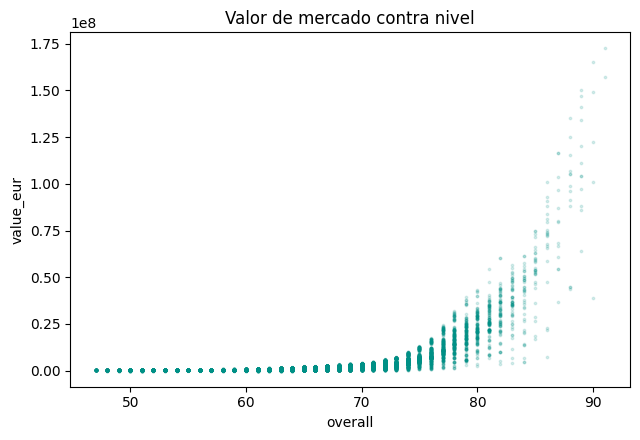

In [ ]:
plt.figure(figsize=(6.5, 4.5))
plt.scatter(valorados["overall"], valorados["value_eur"], s=3, alpha=.15, color="#009086")
plt.xlabel("overall"); plt.ylabel("value_eur"); plt.title("Valor de mercado contra nivel")
plt.tight_layout()
plt.show()

**Qué se ve.** Hasta overall 75 la nube es una línea baja y aplastada contra el eje;
después se abre hacia arriba y se dispara. No hay grupos separados ni una tercera variable
sospechosa: hay **una sola relación, curva**. De los tres movimientos posibles, el que
corresponde a una curva de este tipo es **cambiar la escala**.

**Movimiento 1: escala logarítmica.** El logaritmo convierte multiplicar en sumar. Si la
afirmación es cierta y cada punto de overall multiplica el valor en vez de sumarle una
cantidad fija, en escala logarítmica la nube tiene que enderezarse.

In [ ]:
asociacion(valorados["overall"], np.log(valorados["value_eur"]))

,0
pearson,0.896
spearman,0.883
brecha,-0.013


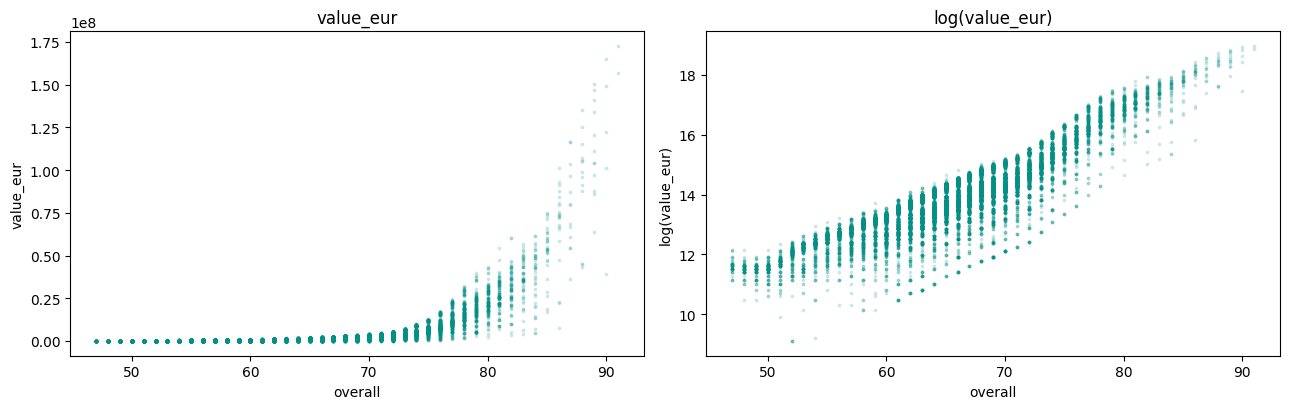

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.2))

for ax, (y, etiqueta) in zip(axes, [(valorados["value_eur"], "value_eur"),
                                    (np.log(valorados["value_eur"]), "log(value_eur)")]):
    ax.scatter(valorados["overall"], y, s=3, alpha=.15, color="#009086")
    ax.set_xlabel("overall"); ax.set_ylabel(etiqueta); ax.set_title(etiqueta)

plt.tight_layout()
plt.show()

**Resultado tras el movimiento.** Pearson pasa de 0,550 a **0,896** y alcanza a
Spearman: la brecha se cierra y la nube de la derecha es una banda recta. **Hipótesis
confirmada**, y con una precisión que la afirmación original no tenía: la relación no es
sólo desigual, es multiplicativa. Cada punto de overall multiplica el valor por un factor
aproximadamente constante.

**Qué hago con eso.** Si en la Unidad 3 hay que predecir el valor, se predice el logaritmo.
Un modelo lineal sobre la variable cruda va a errar sistemáticamente en los extremos:
subestimar a los mejores y sobrestimar al montón.

### H2 · A igual nivel, el joven vale más

**Afirmación.** Entre dos jugadores del mismo nivel, el más joven vale más, porque le quedan
más años de rendimiento por delante.

**Qué espero ver.** Una correlación negativa entre edad y valor. Atención al enunciado: dice
*a igual nivel*, y la primera medida que vamos a calcular no controla el nivel. La
calculamos igual, porque es la que uno calcularía primero.

In [ ]:
h2 = asociacion(valorados["age"], valorados["value_eur"])
h2

,0
pearson,0.029
spearman,0.082
brecha,0.053


In [ ]:
pd.Series({"correlación": semaforo(h2["pearson"], "correlacion")})

,0
correlación,rojo


**Resultado.** Pearson 0,029: **rojo**. Medido así, la edad no tiene absolutamente nada
que ver con el valor, lo que contradice cualquier intuición futbolística. Cuando un número
choca de frente con algo que sabemos que es cierto, lo primero no es aceptar el número: es
mirar qué está midiendo.

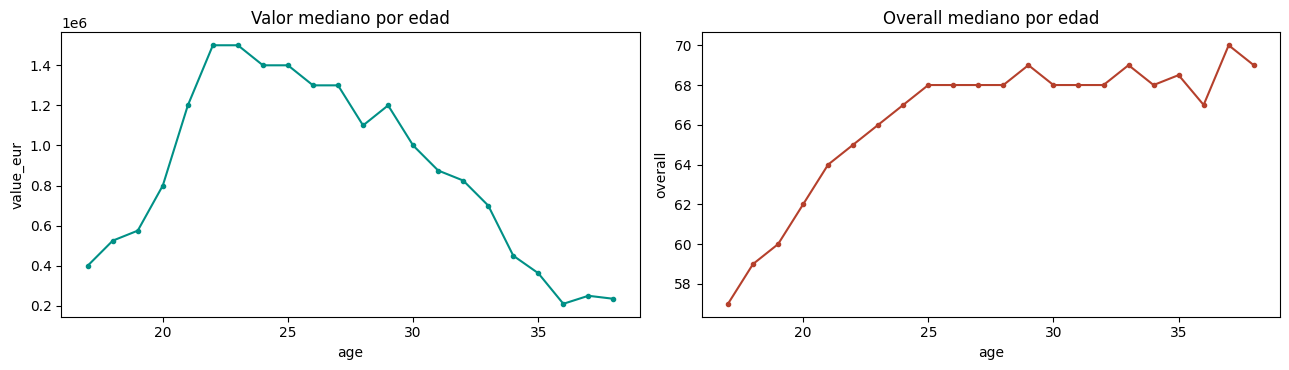

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(13, 3.8))
por_edad = valorados[valorados["age"].between(17, 38)].groupby("age")

por_edad["value_eur"].median().plot(ax=axes[0], color="#009086", marker="o", ms=3)
axes[0].set_title("Valor mediano por edad"); axes[0].set_ylabel("value_eur")

por_edad["overall"].median().plot(ax=axes[1], color="#B5402C", marker="o", ms=3)
axes[1].set_title("Overall mediano por edad"); axes[1].set_ylabel("overall")

plt.tight_layout()
plt.show()

**Qué se ve.** El valor no baja con la edad: **sube hasta los 22 y recién después
baja**. Y el gráfico de al lado explica por qué. El overall también sube con la edad, y
fuerte: de 57 a los 17 hasta 68 a los 25, donde se planta. Los jugadores jóvenes son
baratos porque todavía son peores, no porque sean jóvenes.

Hay entonces dos efectos que empujan en sentidos contrarios y se cancelan, y por eso la
correlación global da cero. Eso es exactamente lo que describe el tercer movimiento:
**controlar una tercera variable**. Si el overall es lo que ensucia la comparación, hay que
comparar jugadores que tengan el mismo overall.

**Movimiento 1: controlar el nivel.** Partimos el dataset en franjas de overall y medimos
adentro de cada una. Usamos todas las franjas y no una sola elegida a dedo, para que la
conclusión no dependa de cuál nos haya tocado mirar.

In [ ]:
franjas = [(50, 60), (60, 65), (65, 70), (70, 75), (75, 95)]
filas = []

for a, b in franjas:
    s = valorados[valorados["overall"].between(a, b)]
    filas.append({"franja": f"{a}-{b}", "jugadores": len(s),
                  "corr edad~log(valor)": round(s["age"].corr(np.log(s["value_eur"])), 3)})

pd.DataFrame(filas)

,franja,jugadores,corr edad~log(valor)
0,50-60,3934,-0.547
1,60-65,5682,-0.752
2,65-70,6618,-0.818
3,70-75,3777,-0.728
4,75-95,1881,-0.496


**Resultado tras el movimiento.** Dentro de cada franja la correlación es fuertemente
negativa: entre −0,50 y −0,82, todas **verdes**. La conclusión no depende del recorte, que
era lo que había que asegurarse. El efecto es más marcado en el medio de la tabla —donde
además está el grueso de los jugadores— y se afloja en los extremos, donde el rango de
valores es más chico.

Vale la pena ver cuánto es eso en dinero, dentro de una franja.

In [ ]:
franja = valorados[valorados["overall"].between(65, 70)]
tramos = franja.groupby(pd.cut(franja["age"], [15, 21, 26, 32, 50]), observed=True)

tramos["value_eur"].median()

,value_eur
age,
"(15, 21]",2100000.0
"(21, 26]",1500000.0
"(26, 32]",1000000.0
"(32, 50]",425000.0


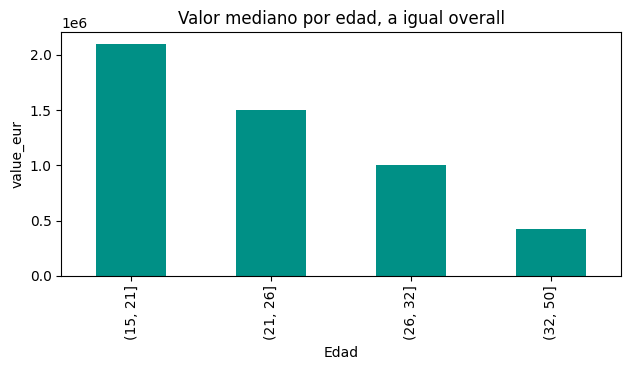

In [ ]:
tramos["value_eur"].median().plot(kind="bar", figsize=(6.5, 3.8), color="#009086",
                                  title="Valor mediano por edad, a igual overall")
plt.xlabel("Edad"); plt.ylabel("value_eur")
plt.tight_layout()
plt.show()

Con el mismo rendimiento, la mediana va de 2,1 millones hasta los 21 años a 425 mil de
33 en adelante: **un factor de cinco**. **Hipótesis confirmada.**

**Qué hago con eso.** La edad entra a cualquier modelo de valor, pero nunca sola: su efecto
aparece solamente junto al overall. Es el ejemplo de manual de por qué una correlación
cercana a cero no significa que no haya relación, y de por qué conviene desconfiar de un
número que contradice algo que sabemos.

### H3 · Los zurdos valen más

**Afirmación.** Los jugadores zurdos tienen mayor valor de mercado que los diestros.

**Qué espero ver.** Se dice que el zurdo escasea y que por eso se paga. Espero una
separación chica pero visible, a favor de los zurdos.

**Por qué esta medida.** Es una comparación entre dos grupos, así que va la separación
estandarizada. Sobre el logaritmo del valor, porque en H1 ya vimos que la variable cruda
tiene una cola larguísima y unos pocos jugadores carísimos moverían el promedio ellos solos.

In [ ]:
zurdos   = np.log(valorados.loc[valorados["preferred_foot"] == "Left",  "value_eur"])
diestros = np.log(valorados.loc[valorados["preferred_foot"] == "Right", "value_eur"])
sep = separacion(zurdos, diestros)

pd.Series({"separación": round(sep, 3), "zona": semaforo(sep, "separacion")})

,0
separación,0.147
zona,rojo


**Resultado.** Separación 0,147: **rojo**. La hipótesis se refuta y acá termina. El
gráfico no hace falta para decidir, pero conviene mirarlo una vez para asociar el número con
lo que se ve.

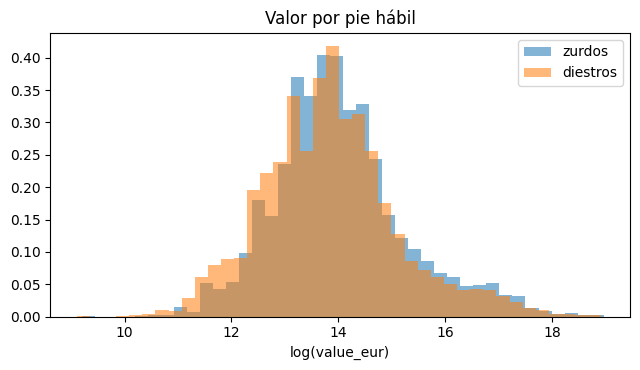

In [ ]:
plt.figure(figsize=(6.5, 3.8))
plt.hist(zurdos,   bins=40, alpha=.55, density=True, label="zurdos")
plt.hist(diestros, bins=40, alpha=.55, density=True, label="diestros")
plt.xlabel("log(value_eur)"); plt.title("Valor por pie hábil"); plt.legend()
plt.tight_layout()
plt.show()

Las dos distribuciones se pisan casi por completo, que es lo que anticipaba el número:
con separación por debajo de 0,2 las curvas comparten más del 90 % de su área. Un corrimiento
mínimo a favor de los zurdos existe, pero no distingue a un jugador de otro.

Como acá termina, aprovechamos para mostrar **qué pasa si uno no se detiene**. Abajo van los
dos movimientos que probaría alguien convencido de que el efecto tiene que estar, uno por vez.

**Movimiento 1: controlar el nivel.** El argumento sería que los zurdos están repartidos
distinto entre niveles, así que comparamos dentro de una franja de overall.

In [ ]:
def sep_valor(sub):
    a = np.log(sub.loc[sub["preferred_foot"] == "Left",  "value_eur"])
    b = np.log(sub.loc[sub["preferred_foot"] == "Right", "value_eur"])
    return round(separacion(a, b), 3)


nivel = valorados[valorados["overall"].between(63, 72)]

pd.Series({"jugadores": len(nivel), "separación": sep_valor(nivel)})

,0
jugadores,10191.000
separación,0.056


Controlando el nivel el efecto **baja** a 0,056, más rojo todavía. Un movimiento que
empeora el resultado es información: dice que el nivel no estaba tapando nada.

**Movimiento 2: partir la población.** El argumento sería que el pie hábil paga sobre todo
en los puestos de banda. Nos quedamos con los extremos.

In [ ]:
extremos = valorados[valorados["best_position"].isin(["RW", "LW"])]

pd.Series({"jugadores": len(extremos), "separación": sep_valor(extremos)})

,0
jugadores,499.000
separación,0.156


Recién recortando a 499 jugadores el número sube a 0,156, y **sigue siendo rojo**. Ahí
se agotó el tope de dos movimientos.

Vale la pena ver qué pasó en el camino: empezamos con 18.925 jugadores y terminamos mirando
499, es decir el 2,6 %. Seguir partiendo el dataset hasta que el número suba es cazar
resultados, no analizar: con suficientes recortes siempre aparece un subgrupo donde el efecto
existe, y no significa nada. El tope de dos movimientos está justamente para esto.

**Qué hago con eso.** Hipótesis refutada. El pie hábil no explica el valor y no va al informe
como si lo hiciera.

# Sección 4: Hipótesis para predecir

Tres hipótesis sobre la pregunta de modelado: qué columnas usar para predecir la posición.
Cambia lo que hay al final. Acá el resultado no es una conclusión sobre el fútbol sino una
**decisión sobre una columna**: entra, sale, o se transforma. Y esa decisión se toma ahora,
en el análisis exploratorio, no cuando el modelo ya está entrenado.

### H4 · Medir el pase y medir la gambeta es medir lo mismo

**Afirmación.** `passing` y `dribbling` son dos nombres para una misma cualidad —el jugador
que se lleva bien con la pelota puntúa alto en las dos—, así que darle las dos columnas al
modelo no agrega información sobre darle una sola.

**Qué espero ver.** Una nube apretada alrededor de una diagonal, y que cada una de las dos
sirva más o menos igual para separar posiciones.

**Por qué estas medidas.** Hacen falta dos, porque la afirmación tiene dos partes. Que las
columnas se muevan juntas se ve con una asociación. Pero moverse juntas no alcanza: lo que
importa es si **aportan lo mismo al problema**, y eso se prueba con η² contra la posición —
si son intercambiables, combinarlas no debería superar a la mejor de las dos.

In [ ]:
asociacion(df["passing"], df["dribbling"])

,0
pearson,0.864
spearman,0.855
brecha,-0.009


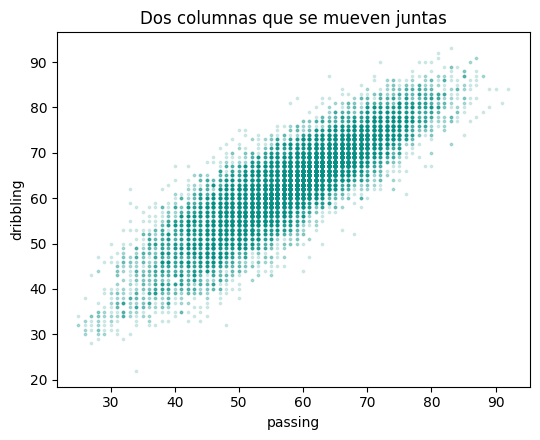

In [ ]:
df.plot.scatter(x="passing", y="dribbling", s=3, alpha=.15, figsize=(5.5, 4.5),
                color="#009086", title="Dos columnas que se mueven juntas")
plt.tight_layout()
plt.show()

**Resultado parcial.** Pearson 0,864 y la nube efectivamente apretada contra la
diagonal. Pero esto sólo dice que se mueven juntas, no que sobre una de las dos. La segunda
medida es la que decide: comparamos cuánto explica la posición a cada una por separado, y a
las dos combinadas en una sola columna.

In [ ]:
pd.Series({"passing":   eta2(df["passing"],   df["best_position"]),
           "dribbling": eta2(df["dribbling"], df["best_position"]),
           "promedio":  eta2((df["passing"] + df["dribbling"]) / 2, df["best_position"])}).round(3)

,0
passing,0.286
dribbling,0.316
promedio,0.303


**Resultado.** 0,286 y 0,316 por separado; combinadas, 0,303. Combinarlas **no le gana
a la mejor de las dos**: la información que traen es la misma. **Hipótesis confirmada.**

Ojo con el detalle: la diferencia entre 0,286 y 0,316 es chica y no es el argumento. El
argumento es que sumarlas no aporta nada. Cuál de las dos se queda es casi indistinto; lo
que no es indistinto es quedarse con las dos.

**Qué hago con eso.** Entra `dribbling`, que es la más alta, y `passing` sale. Con variables
redundantes el modelo no mejora, y la interpretación empeora: el peso se reparte entre dos
columnas que dicen lo mismo, y ninguna de las dos parece importante.

### H5 · `player_positions` es la mejor columna que tenemos

**Afirmación.** `player_positions` describe exactamente aquello que queremos predecir, así
que tiene que ser la columna más informativa del dataset para este problema.

**Qué espero ver.** Que la posición objetivo aparezca dentro de esa lista en la enorme
mayoría de las filas.

**Por qué esta medida.** Es una composición: qué proporción de las filas tiene el valor
objetivo adentro de la columna candidata. Medimos dos cosas, si la contiene y si además es
la primera de la lista.

In [ ]:
lista    = df["player_positions"].str.split(",").apply(lambda ps: [p.strip() for p in ps])
contiene = [b in ps for b, ps in zip(df["best_position"], lista)]
primera  = df["player_positions"].str.split(",").str[0].str.strip() == df["best_position"]

pd.Series({"la contiene": np.mean(contiene), "es la primera": primera.mean()}).round(3)

,0
la contiene,0.857
es la primera,0.749


**Resultado.** La contiene en el **85,7 %** de las filas y es la primera listada en el
**74,9 %**. La afirmación se confirma con creces, y ese es justamente el problema.

Un modelo que use esta columna acertaría el 85 % de las veces sin haber aprendido nada del
juego: le estaríamos pasando la respuesta escrita de otra forma. Eso se llama **fuga de
información**, y no se detecta por el desempeño —el modelo va a dar buenísimo— sino
preguntándose de dónde sale cada columna. Una columna que es demasiado buena para ser cierta
casi nunca es cierta.

**Movimiento: revisar las columnas vecinas.** Si una filtra, conviene mirar las otras que
describen lo mismo antes de dar el tema por cerrado.

In [ ]:
# club_position, en las filas donde indica una posición táctica y no SUB o RES
tacticos = df[~df["club_position"].isin(["SUB", "RES"])]

coincide = (tacticos["club_position"] == tacticos["best_position"]).mean()

pd.Series({"filas tácticas": f"{len(tacticos):,}", "coincide con best_position": f"{coincide:.1%}"})

,0
filas tácticas,"7,293"
coincide con best_position,37.0%


`club_position` coincide en el 37 % de esas filas: filtra menos, pero filtra igual.
**Hipótesis confirmada y columna descartada**, que es la única de las seis donde confirmar
la afirmación es una mala noticia.

**Qué hago con eso.** Las dos salen del conjunto de features, y queda la regla general: antes
de darle una columna al modelo, preguntarse **si esa columna existiría en el momento de
predecir**. Si la respuesta ya está adentro, no es una feature. Es el error más caro de la
unidad que viene, y se detecta acá, no cuando el modelo da 99 % de acierto.

### H6 · La edad sirve para predecir la posición

**Afirmación.** La edad ayuda a distinguir una posición de otra.

**Qué espero ver.** Poco, pero algo: los arqueros deberían durar más años que el resto, y
los puestos de banda, que dependen de la velocidad, deberían ser más jóvenes. Espero un η²
chico y distinto de cero.

**Por qué esta medida.** Es una comparación entre muchos grupos —quince posiciones— así que
va η²: qué proporción de la variación de la edad se explica por la posición.

In [ ]:
e6 = eta2(df["age"], df["best_position"])

pd.Series({"eta2": round(e6, 3), "zona": semaforo(e6, "eta2")})

,0
eta2,0.054
zona,amarillo


**Resultado.** η² 0,054: **amarillo**, apenas por encima del corte. No alcanza para
afirmar ni para descartar. Vamos al gráfico a ver de dónde sale ese poquito.

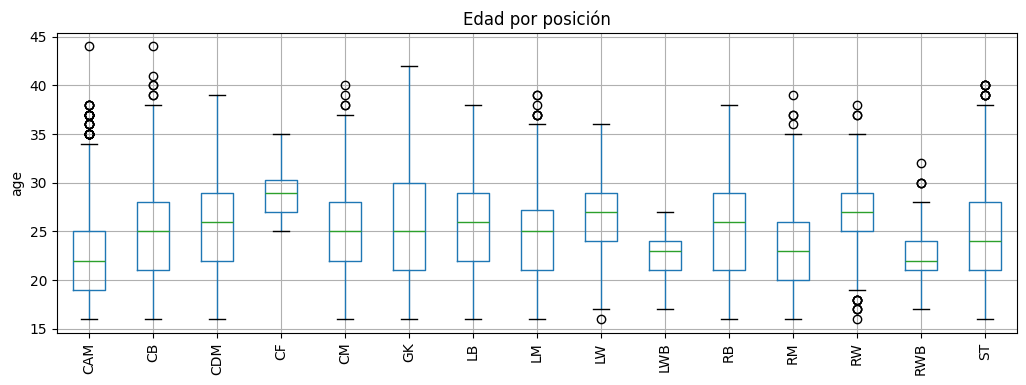

In [ ]:
df.boxplot(column="age", by="best_position", figsize=(12, 4), rot=90)
plt.title("Edad por posición"); plt.suptitle(""); plt.xlabel(""); plt.ylabel("age")
plt.show()

**Qué se ve, y conviene mirarlo con cuidado porque contradice lo que esperábamos.**
Los arqueros **no** están arriba: su mediana es 25, la misma que la de media tabla. Lo que
tienen de distinto es la caja más larga de todas, de 21 a 30 años, con casos desde los 16
hasta los 42: entran jóvenes y se retiran tarde. Y los puestos de banda tampoco son todos
jóvenes — los laterales volantes están entre los más jóvenes, pero los extremos ofensivos
están entre los más veteranos.

Lo que sí se despega es el centrodelantero, con mediana 29. Pero son **40 jugadores** sobre
18.936: una caja construida con esa cantidad no puede sostener una conclusión sobre el resto.

Y lo principal: las medianas de las quince posiciones van de 22 a 29 —siete años— mientras
que las cajas de las posiciones más pobladas abarcan entre seis y nueve. La variación **dentro** de cada posición es más
grande que la variación **entre** posiciones, y eso es exactamente lo que dice un η² de 0,054.
El ojo se va a las medianas y no registra el ancho de las cajas; por eso el gráfico solo
habría hecho afirmar de más.

**Movimiento 1: controlar el nivel.** El boxplot no puede distinguir «esta posición es más
veterana» de «esta posición la juegan jugadores de mayor nivel, que son más veteranos». Es el
mismo razonamiento de H2: si el overall empuja a las dos cosas, hay que medir a nivel parejo.

In [ ]:
mismo_nivel = df[df["overall"].between(63, 72)]
e6_nivel = eta2(mismo_nivel["age"], mismo_nivel["best_position"])

pd.Series({"eta2": round(e6_nivel, 3), "zona": semaforo(e6_nivel, "eta2")})

,0
eta2,0.077
zona,amarillo


Sube de 0,054 a **0,077**: el nivel efectivamente tapaba una parte del efecto. Pero
sigue **amarillo**, así que todavía no alcanza. Queda un movimiento.

**Movimiento 2: partir la población.** El candidato sale del mismo gráfico: los arqueros son
el grupo con la caja más ancha, y esa dispersión interna es varianza que η² no puede
atribuir a la posición. Sacándolos, el resto de los grupos queda más parejo.

In [ ]:
sin_arqueros = mismo_nivel[mismo_nivel["best_position"] != "GK"]
e6_sin = eta2(sin_arqueros["age"], sin_arqueros["best_position"])

pd.Series({"eta2": round(e6_sin, 3), "zona": semaforo(e6_sin, "eta2")})

,0
eta2,0.066
zona,amarillo


**Resultado tras los dos movimientos.** 0,054, después 0,077, después **0,066**. El
segundo movimiento no sólo no ayudó: bajó el número. Los arqueros no ensuciaban la medida,
aportaban parte de la poca señal que había — que es lo que uno debería haber sospechado al
ver que su caja era la más larga y no la más alta.

Agotamos el tope y nunca salimos del amarillo.

**Qué hago con eso. Inconclusa.** La edad explica algo de la posición, pero tan poco que el
análisis exploratorio no puede decidir si vale la pena incluirla. Se la deja como candidata
débil y la decisión la toma el modelo de la Unidad 3, comparando su desempeño con y sin ella.
Escribir *inconclusa* es más honesto que forzar un veredicto, y bastante más útil: le avisa
al que siga que ese punto quedó abierto y por qué.

# Sección 5: El puente al proyecto propio

Las mismas dos preguntas se aplican a tu dataset, y conviene escribirlas antes de tocar
código: **qué querés responder** y **qué querés predecir**. Del primer par salen las
hipótesis de negocio; del segundo, las de features.

Cuatro cosas de este notebook se trasladan tal cual.

**El orden.** La afirmación y lo que esperás ver se escriben antes de correr la medida. Es
la parte más fácil de saltearse y la que sostiene todo lo demás.

**Las plantillas y sus medidas.** Comparación, asociación y composición cubren casi todo lo
que vas a querer preguntar, y la medida viene con la plantilla. No se elige después de ver
cuál da mejor.

**El semáforo y el tope de dos movimientos.** Verde y rojo terminan la hipótesis. Amarillo
habilita hasta dos movimientos —partir la población, controlar una tercera variable, cambiar
la escala— elegidos mirando el gráfico, y después se escribe *inconclusa*.

**El chequeo de fuga.** Antes de la Entrega 3, para cada columna que pienses darle al modelo:
¿existiría en el momento de predecir?

In [ ]:
# Las seis hipótesis, su medida y la decisión que salió de cada una
pd.DataFrame(
    [("H1 unos pocos valen mucho más", "responder", "asociación",  "brecha 0.33 → log 0.896",   "verde",    "predecir el log del valor"),
     ("H2 a igual nivel el joven vale más", "responder", "asociación", "-0.50 a -0.82 por franja", "verde",  "edad entra junto al overall"),
     ("H3 los zurdos valen más",      "responder", "comparación", "separación 0.147",          "rojo",     "refutada, no va al informe"),
     ("H4 pase y gambeta miden igual", "predecir", "comparación", "eta2 0.316 vs 0.303 juntas", "verde",   "entra dribbling, sale passing"),
     ("H5 player_positions es la mejor", "predecir", "composición", "contiene la respuesta 85.7%", "verde", "es fuga: sale"),
     ("H6 la edad predice la posición", "predecir", "comparación", "eta2 0.054 → 0.077 → 0.066", "amarillo", "inconclusa, decide el modelo")],
    columns=["hipótesis", "pregunta", "plantilla", "medida", "zona", "decisión"])

,hipótesis,pregunta,plantilla,medida,zona,decisión
0,H1 unos pocos valen mucho más,responder,asociación,brecha 0.33 → log 0.896,verde,predecir el log del valor
1,H2 a igual nivel el joven vale más,responder,asociación,-0.50 a -0.82 por franja,verde,edad entra junto al overall
2,H3 los zurdos valen más,responder,comparación,separación 0.147,rojo,"refutada, no va al informe"
3,H4 pase y gambeta miden igual,predecir,comparación,eta2 0.316 vs 0.303 juntas,verde,"entra dribbling, sale passing"
4,H5 player_positions es la mejor,predecir,composición,contiene la respuesta 85.7%,verde,es fuga: sale
5,H6 la edad predice la posición,predecir,comparación,eta2 0.054 → 0.077 → 0.066,amarillo,"inconclusa, decide el modelo"


### Cierre

Seis hipótesis, seis decisiones. Dos se confirmaron después de un movimiento, una se refutó
en el primer número, dos definieron qué columnas quedan afuera del modelo, y una quedó
inconclusa. Ninguna de las seis se contestó con un gráfico.

Los gráficos hicieron otra cosa, que es la que conviene llevarse: explicaron el número que
ya habíamos calculado y **decidieron cuál era el movimiento siguiente**. La curva de H1 pidió
cambiar la escala, las dos líneas cruzadas de H2 pidieron controlar el nivel, las cajas
anchas de H6 avisaron que el ojo estaba afirmando de más. Esa división del trabajo
—el número decide, el gráfico explica— es todo el método.